### Experiment notes — 1

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 2

Project goals and evaluation criteria. Dataset provenance, format and train/test split. Key techniques: K-NN.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 3

Introduction and motivation for the analysis. Assignment scope and evaluation requirements. Key techniques: K-NN.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 4

Dataset overview and problem setup.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [1]:
from PIL import Image
img = Image.open('data/train/0/4-3.jpg')  # plot
img  # display plot from PIL import Image
img = Image.open('data/train/63/晋_879_0.jpg')  # plot
img  # display plot

In [2]:
import numpy as np
pixels = np.array(img)  # for numpy matrix
pixels.shape

(20, 20)

### Experiment notes — 7

Train and compare machine learning models.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [3]:
# conda install -c conda-forge opencv

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']  # Implementation note
plt.rcParams['axes.unicode_minus'] = False  # display

%matplotlib inline

In [4]:
# ================= parameters =================
val_size = 0.3 # validation set ratio
RANDOM_SEED = 42
metrics = ['euclidean', 'manhattan', 'chebyshev', 'minkowski']
weights = ['uniform', 'distance']
k_range = range(1, 21)                # K value

In [5]:
# ================= 1. image load and vector function =================
# use OpenCV (cv2) output numpy ， feature extraction and
def load_data(data_dir, img_size=(32, 32)):
    """
    从文件夹加载图像，返回特征矩阵X和标签列表y。
    每个子文件夹名即为标签y。
    """
    X = []
    y = []
    for label in os.listdir(data_dir):
        label_dir = os.path.join(data_dir, label)
        if not os.path.isdir(label_dir):
            continue
        for img_name in os.listdir(label_dir):
            img_path = os.path.join(label_dir, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE) 
            if img is None:
                continue
            img = cv2.resize(img, img_size)                   # one
            X.append(img.flatten())                           # for one vector
            y.append(label)
    return np.array(X), np.array(y)

In [6]:
# training image 'data/train'
X_train, y_train = load_data('data/train', img_size=(20, 20))
print(f"训练集样本数: {X_train.shape[0]} 个样本，每个样本维度 {X_train.shape[1]}")

# testing image 'data/test'
X_test, y_test = load_data('data/test', img_size=(20, 20))
print(f"测试集样本数: {len(X_test)} 个样本，每个测试集维度 {X_test.shape[1]}")

训练集样本数: 15954 个样本，每个样本维度 400
测试集样本数: 4665 个样本，每个测试集维度 400


In [7]:
# plot one load ： plot table vector and label
# 5 training sample vector and label
for i, (x, y) in enumerate(zip(X_train[100:105], y_train[100:105]), start=1):
    print(f"训练集示例{i}: {x}\n对应标签: {y}\n")

训练集示例1: [  0   6   0   0   2   0   4   1   3   0   0   0   0   2   2   0   0   0
   0   0   0   0   4   2   5   2   1   0   0 137 134 136  84   0   3   3
   0   0   0   0   2   0   1   7   0 208 227  85 215 255 254 255 157   0
   0   0   0   0   0   0   0   3   3   0   4 238 254 251 255 252 253 255
 255  74   0   3   0   0   0   0   0   0   2   2   1 233 255 255 255 254
 255 247 255  71   0   1   0   0   0   0   3   1   1   0   1 236 252 104
 249 252 250 255 250  73   4   2   0   0   0   0   0   0   1   0   2 239
 255 139  72 252 255 252 253 121   0   1   0   0   0   0   0   1   0   2
  93 245 255 253 255 255 255 255 252 255   2   1   0   0   0   0   1   5
   0   0   6 235 255 255  10 255 253 254 254  77   1   0   0   0   0   0
   0   2   0   1   2 237 229 169 254 254 255 250   1   1   0   2   0   0
   0   0   1   0   5   4   0  77 185   2 247 255 252 254 107   2   4   0
   0   0   0   0   0   5   2   0   1 236 186   1   0 255 255 251 162   0
   0   4   0   0   0   0   0   0   3   5   

### Experiment notes — 13

Core assignment objectives.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [8]:
# ================= 2. build K-NN model prediction ： model =================
# define K-NN model （ distance
n_neighbors = 3

knn_basic = KNeighborsClassifier(n_neighbors=n_neighbors)
pipeline = make_pipeline(StandardScaler(), knn_basic)
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
acc_basic = accuracy_score(y_test, y_pred)
print(f"K={n_neighbors} 时的测试准确率: {acc_basic * 100:.2f}%")

K=3 时的测试准确率: 42.23%


### Experiment notes — 15

Core assignment objectives.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

k=1对应准确率：41.26%
k=2对应准确率：41.16%
k=3对应准确率：42.23%
k=4对应准确率：42.55%
k=5对应准确率：43.34%
k=6对应准确率：43.43%
k=7对应准确率：43.58%
k=8对应准确率：43.60%
k=9对应准确率：43.88%
k=10对应准确率：43.90%
k=11对应准确率：43.92%
k=12对应准确率：43.84%
k=13对应准确率：44.07%
k=14对应准确率：44.01%
k=15对应准确率：43.94%
k=16对应准确率：43.82%
k=17对应准确率：43.67%
k=18对应准确率：43.60%
k=19对应准确率：43.54%
k=20对应准确率：43.28%


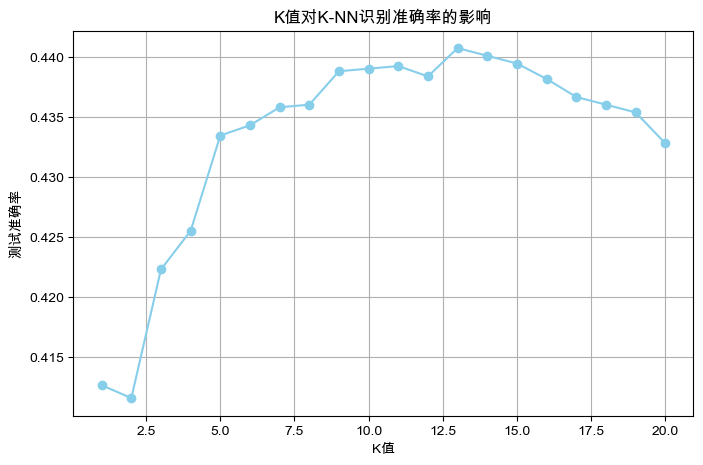

In [9]:
# ================= 3. K value accuracy =================
# iterate K = 1 ~ 20， record testing accuracy ， plot analysis
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipeline = make_pipeline(StandardScaler(), knn)
    pipeline.fit(X_train, y_train)   # training set training
    y_pred = pipeline.predict(X_test)    
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"k={k}对应准确率：{acc*100:.2f}%")

# plot K value and accuracy
plt.figure(figsize=(8,5))
plt.plot(k_range, accuracies, marker='o', color='skyblue')
plt.xlabel('K值')
plt.ylabel('测试准确率')
plt.title('K值对K-NN识别准确率的影响')
plt.grid(True)

### Experiment notes — 17

Interpretation of results and model behavior. Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 18

Evaluate a held-out test split. Core assignment objectives.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 19

Additional experiments and alternative baselines.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [10]:
# split validation set
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train, y_train, test_size=val_size, random_state=RANDOM_SEED , stratify=y_train
)

### Experiment notes — 21

Evaluate out-of-sample predictions.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [11]:
# validation set best K
val_accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipeline = make_pipeline(StandardScaler(), knn)
    pipeline.fit(X_train_new, y_train_new)   # training set training
    y_pred_val = pipeline.predict(X_val)     # validation set prediction
    acc = accuracy_score(y_val, y_pred_val)
    val_accuracies.append(acc)

# to best K
best_k = k_range[val_accuracies.index(max(val_accuracies))]
print(f"最佳 K = {best_k}, 验证集准确率 = {max(val_accuracies):.4f}")

最佳 K = 1, 验证集准确率 = 0.9649


In [12]:
# last all training set （X_train） again training ， test set evaluate
final_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_pipeline.fit(X_train, y_train)
y_pred_test = final_pipeline.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print(f"测试集最终准确率: {test_acc:.4f}")

测试集最终准确率: 0.4126


### Experiment notes — 24

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [15]:
# ================= 4. different distance comparison （ validation set hyperparameter tuning ） =================
best_k = 1   # validation set best K value 1
metric_acc = {}

for metric in metrics:
    knn = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    pipeline = make_pipeline(StandardScaler(), knn)
    pipeline.fit(X_train_new, y_train_new)
    y_pred_val = pipeline.predict(X_val)
    acc_val = accuracy_score(y_val, y_pred_val)

    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    metric_acc[metric] = acc_val, acc
    
    print(f"距离度量 {metric}: 验证集准确率 = {acc_val*100:.2f}%， 测试集准确率 = {acc*100:.2f}%")

print(f"\n ⚠️注意：参数选择依据是验证集，而不是测试集。测试集只用于最终评估。")

距离度量 euclidean: 验证集准确率 = 96.49%， 测试集准确率 = 41.61%
距离度量 manhattan: 验证集准确率 = 96.74%， 测试集准确率 = 60.39%
距离度量 chebyshev: 验证集准确率 = 83.79%， 测试集准确率 = 8.70%
距离度量 minkowski: 验证集准确率 = 96.49%， 测试集准确率 = 41.61%

 ⚠️注意：参数选择依据是验证集，而不是测试集。测试集只用于最终评估。


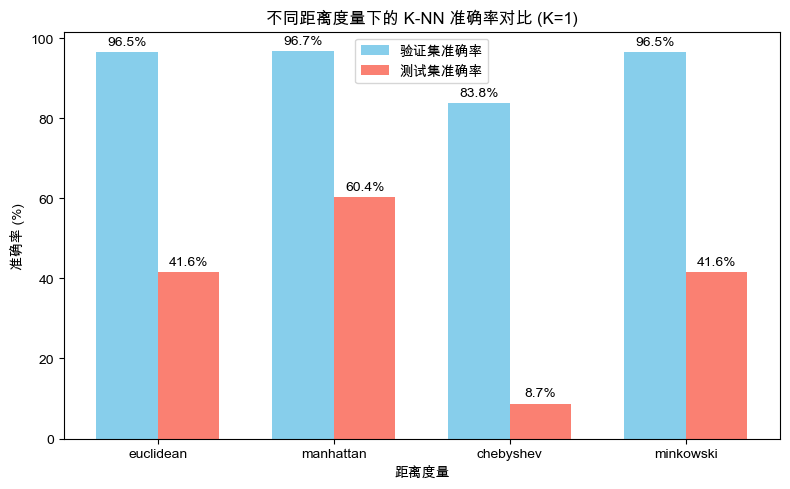

In [14]:
# take and accuracy （ convert for
metrics = list(metric_acc.keys())
val_acc = [metric_acc[m][0] * 100 for m in metrics]
test_acc = [metric_acc[m][1] * 100 for m in metrics]

# plot grouped plot
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, val_acc, width, label='验证集准确率', color='skyblue')
rects2 = ax.bar(x + width/2, test_acc, width, label='测试集准确率', color='salmon')

ax.set_xlabel('距离度量')
ax.set_ylabel('准确率 (%)')
ax.set_title('不同距离度量下的 K-NN 准确率对比 (K=1)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

# display value
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()

### Experiment notes — 27

Interpretation of results and model behavior. Evaluate a held-out test split. Key techniques: K-NN, PCA, SVM.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 28

Review the implementation and results for this stage of the experiment. Key techniques: K-NN.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

准确率：
k=1：平权模型-验证集96.49%，测试集41.61%；加权模型-验证集96.49%，测试集41.61%
k=2：平权模型-验证集95.32%，测试集41.63%；加权模型-验证集96.49%，测试集41.61%
k=3：平权模型-验证集95.59%，测试集42.77%；加权模型-验证集96.26%，测试集41.65%
k=4：平权模型-验证集95.03%，测试集43.47%；加权模型-验证集96.16%，测试集42.29%
k=5：平权模型-验证集95.13%，测试集43.92%；加权模型-验证集95.86%，测试集43.15%
k=6：平权模型-验证集94.78%，测试集43.39%；加权模型-验证集95.91%，测试集43.71%
k=7：平权模型-验证集94.80%，测试集43.37%；加权模型-验证集95.80%，测试集43.69%
k=8：平权模型-验证集94.30%，测试集43.49%；加权模型-验证集95.51%，测试集43.73%
k=9：平权模型-验证集94.05%，测试集43.60%；加权模型-验证集95.26%，测试集43.58%
k=10：平权模型-验证集93.71%，测试集43.43%；加权模型-验证集95.26%，测试集43.43%
k=11：平权模型-验证集93.69%，测试集42.92%；加权模型-验证集94.97%，测试集42.87%
k=12：平权模型-验证集93.42%，测试集43.09%；加权模型-验证集94.94%，测试集43.17%
k=13：平权模型-验证集93.27%，测试集42.77%；加权模型-验证集94.71%，测试集42.70%
k=14：平权模型-验证集93.36%，测试集42.81%；加权模型-验证集94.74%，测试集42.94%
k=15：平权模型-验证集93.27%，测试集42.36%；加权模型-验证集94.55%，测试集42.68%
k=16：平权模型-验证集93.11%，测试集42.32%；加权模型-验证集94.51%，测试集42.81%
k=17：平权模型-验证集93.02%，测试集42.36%；加权模型-验证集94.38%，测试集42.70%
k=18：平权模型-验证集92.94%，测试集42.21%；加权模型-验证集94.44%，测试集42.57%
k=19：平权模型-验证集9

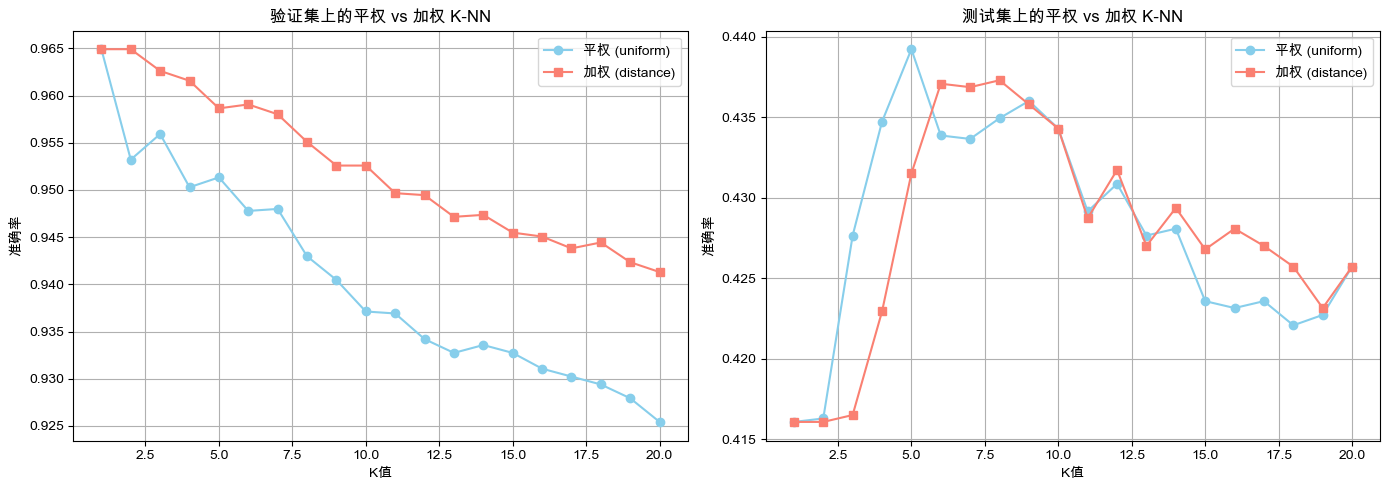

In [16]:
# ================= 5. and K-NN comparison （ validation set hyperparameter tuning ） =================
uniform_val_acc = []   # validation set accuracy
distance_val_acc = []  # validation set accuracy
uniform_test_acc = []  # test set accuracy
distance_test_acc = [] # test set accuracy

print("准确率：")
for k in k_range:
    # model
    knn_uniform = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    pipe_uniform = make_pipeline(StandardScaler(), knn_uniform)
    pipe_uniform.fit(X_train_new, y_train_new)
    
    # validation set evaluate
    y_pred_val_uniform = pipe_uniform.predict(X_val)
    acc_uni_val = accuracy_score(y_val, y_pred_val_uniform)
    uniform_val_acc.append(acc_uni_val)
    # test set evaluate （ plot ， and hyperparameter tuning
    y_pred_test_uniform = pipe_uniform.predict(X_test)
    acc_uni_test = accuracy_score(y_test, y_pred_test_uniform)
    uniform_test_acc.append(acc_uni_test)
    
    # model
    knn_distance = KNeighborsClassifier(n_neighbors=k, weights='distance')
    pipe_distance = make_pipeline(StandardScaler(), knn_distance)
    pipe_distance.fit(X_train_new, y_train_new)
    
    y_pred_val_distance = pipe_distance.predict(X_val)
    acc_dist_val = accuracy_score(y_val, y_pred_val_distance)
    distance_val_acc.append(acc_dist_val)
    
    y_pred_test_distance = pipe_distance.predict(X_test)
    acc_dist_test = accuracy_score(y_test, y_pred_test_distance)
    distance_test_acc.append(acc_dist_test)
    
    print(f"k={k}：平权模型-验证集{acc_uni_val*100:.2f}%，测试集{acc_uni_test*100:.2f}%；加权模型-验证集{acc_dist_val*100:.2f}%，测试集{acc_dist_test*100:.2f}%")

print(f"\n ⚠️注意：参数选择依据是验证集，而不是测试集。测试集只用于最终评估。")
# ================= plot comparison plot （ validation set vs test set ） =================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# plot ： validation set results
ax1.plot(k_range, uniform_val_acc, 'o-', label='平权 (uniform)', color='skyblue')
ax1.plot(k_range, distance_val_acc, 's-', label='加权 (distance)', color='salmon')
ax1.set_xlabel('K值')
ax1.set_ylabel('准确率')
ax1.set_title('验证集上的平权 vs 加权 K-NN')
ax1.legend()
ax1.grid(True)

# plot ： test set results
ax2.plot(k_range, uniform_test_acc, 'o-', label='平权 (uniform)', color='skyblue')
ax2.plot(k_range, distance_test_acc, 's-', label='加权 (distance)', color='salmon')
ax2.set_xlabel('K值')
ax2.set_ylabel('准确率')
ax2.set_title('测试集上的平权 vs 加权 K-NN')
ax2.legend()
ax2.grid(True)

plt.tight_layout()

### Experiment notes — 30

Interpretation of results and model behavior. Inspect and engineer input features.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 31

Fit models and inspect generalization. Evaluate a held-out test split.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

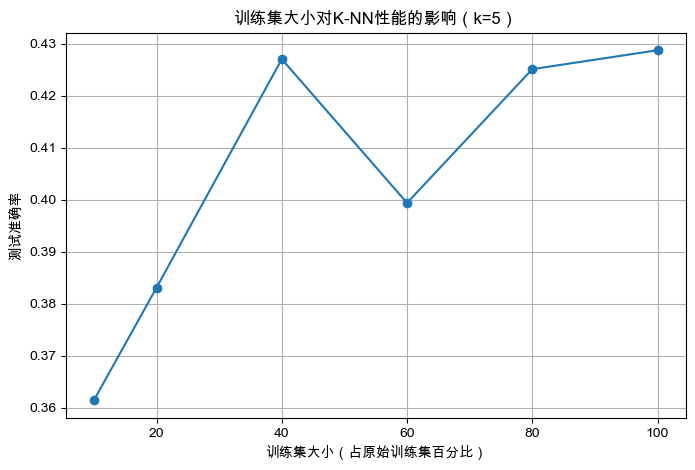

In [17]:
# ================= 6. training set size testing results =================
train_sizes = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]  # training set training set ratio
train_scores = []  # training set accuracy
test_scores = []   # test set accuracy
best_k = 5

for size in train_sizes:
    # from training set take sample
    n_samples = int(len(X_train) * size)
    indices = np.random.choice(len(X_train), n_samples, replace=False)
    X_train_sub = X_train[indices]
    y_train_sub = y_train[indices]

    knn = KNeighborsClassifier(n_neighbors=best_k, weights='distance')
    pipe = make_pipeline(StandardScaler(), knn)
    pipe.fit(X_train_sub, y_train_sub)

    # test set evaluate （ test set
    y_pred = pipe.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    test_scores.append(test_acc)

# plot
plt.figure(figsize=(8,5))
plt.plot([s * 100 for s in train_sizes], test_scores, marker='o')
plt.xlabel('训练集大小（占原始训练集百分比）')
plt.ylabel('测试准确率')
plt.title('训练集大小对K-NN性能的影响（k=5）')
plt.grid(True)
plt.show()

### Experiment notes — 33

Interpretation of results and model behavior. Fit models and inspect generalization.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [18]:
# ================= 7. iterate to best parameters （ validation set hyperparameter tuning ， K、 distance 、 weights ） =================
best_acc = 0
best_params = None

for k in k_range:
    for metric in metrics:
        for weight in weights:
            knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weight)
            pipeline = make_pipeline(StandardScaler(), knn)
            pipeline.fit(X_train_new, y_train_new)
            y_pred_val = pipeline.predict(X_val)
            acc = accuracy_score(y_val, y_pred_val)
            if acc > best_acc:
                best_acc = acc
                best_params = (k, metric, weight)
                print(f"发现更好的参数: K={k}, metric={metric}, weight={weight}, 验证集准确率={acc:.4f}")

print("\n========== 最终结果 ==========")
print(f"最佳 K = {best_params[0]}")
print(f"最佳距离度量 = {best_params[1]}")
print(f"最佳权重策略 = {best_params[2]}")
print(f"验证集最佳准确率 = {best_acc:.4f}")

# use best parameters training set （X_train） training ， test set evaluate
final_pipeline = make_pipeline(StandardScaler(), 
                               KNeighborsClassifier(n_neighbors=best_params[0],
                                                    metric=best_params[1],
                                                    weights=best_params[2]))
final_pipeline.fit(X_train, y_train)
y_pred_test = final_pipeline.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print(f"测试集最终准确率 = {test_acc:.4f}")

发现更好的参数: K=1, metric=euclidean, weight=uniform, 验证集准确率=0.9649
发现更好的参数: K=1, metric=manhattan, weight=uniform, 验证集准确率=0.9674

========== 最终结果 ==========
最佳 K = 1
最佳距离度量 = manhattan
最佳权重策略 = uniform
验证集最佳准确率 = 0.9674
测试集最终准确率 = 0.6028


### Experiment notes — 35

Interpretation of results and model behavior. Fit models and inspect generalization.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 36

Review the implementation and results for this stage of the experiment. Key techniques: SVM.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [19]:
import gc
gc.collect()

3311

In [76]:
# SVM
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# build standardization SVM
svm_pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42))

# define parameters
param_grid = {
    'svc__C': [0.1, 1, 10, 100],          # Implementation note
    'svc__gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto']  # RBF
}

# training set （ cross-validation
grid_svm = GridSearchCV(svm_pipeline, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_svm.fit(X_train_new, y_train_new)

print("SVM 最佳参数:", grid_svm.best_params_)
print("交叉验证最佳准确率:", grid_svm.best_score_)

# validation set evaluate
y_val_pred = grid_svm.best_estimator_.predict(X_val)
val_acc = accuracy_score(y_val, y_val_pred)
print("验证集准确率:", val_acc)

# test set final evaluate
y_test_pred = grid_svm.best_estimator_.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
print("测试集准确率:", test_acc)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
SVM 最佳参数: {'svc__C': 10, 'svc__gamma': 0.001}
交叉验证最佳准确率: 0.9609567896557164
验证集准确率: 0.972634217672864
测试集准确率: 0.3798499464094319


In [79]:
# Implementation note
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_rf.fit(X_train_new, y_train_new)   # note ： standardization

print("随机森林最佳参数:", grid_rf.best_params_)
print("交叉验证最佳准确率:", grid_rf.best_score_)

# validation set evaluate
y_val_pred_rf = grid_rf.best_estimator_.predict(X_val)
val_acc_rf = accuracy_score(y_val, y_val_pred_rf)
print("验证集准确率:", val_acc_rf)

# test set evaluate
y_test_pred_rf = grid_rf.best_estimator_.predict(X_test)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)
print("测试集准确率:", test_acc_rf)

Fitting 3 folds for each of 108 candidates, totalling 324 fits
随机森林最佳参数: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
交叉验证最佳准确率: 0.9498520339338334
验证集准确率: 0.9632337580948402
测试集准确率: 0.692390139335477


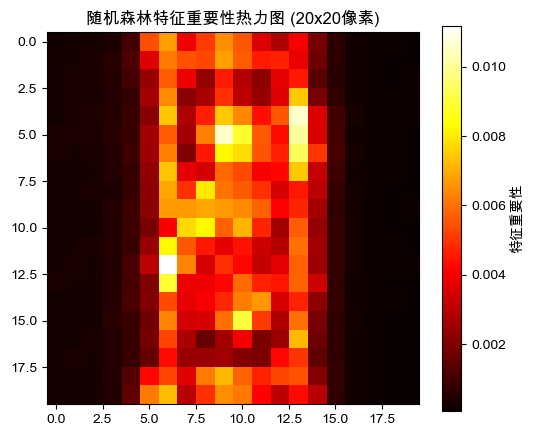

最重要的像素数量: 40


In [81]:
# take best model
best_rf = grid_rf.best_estimator_
importances = best_rf.feature_importances_

# importance for image （ image 20x20
img_size = 20
importance_img = importances.reshape(img_size, img_size)

# plot plot
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.imshow(importance_img, cmap='hot')
plt.colorbar(label='特征重要性')
plt.title('随机森林特征重要性热力图 (20x20像素)')
plt.show()

# 10%
threshold = np.percentile(importances, 90)
important_pixels = np.where(importances >= threshold)
print(f"最重要的像素数量: {len(important_pixels[0])}")

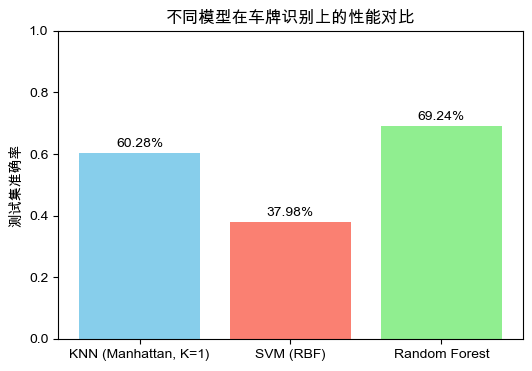

In [80]:
models = ['KNN (Manhattan, K=1)', 'SVM (RBF)', 'Random Forest']
test_accs = [0.6028, test_acc, test_acc_rf]   # value

plt.figure(figsize=(6,4))
plt.bar(models, test_accs, color=['skyblue', 'salmon', 'lightgreen'])
plt.ylabel('测试集准确率')
plt.title('不同模型在车牌识别上的性能对比')
plt.ylim(0, 1)
for i, v in enumerate(test_accs):
    plt.text(i, v+0.02, f'{v:.2%}', ha='center')
plt.show()

### Experiment notes — 42

Interpretation of results and model behavior. Evaluate out-of-sample predictions. Key techniques: SVM.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*